In [ ]:
from datasets import load_from_disk
ds = load_from_disk('/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-neighborhood-tokenizer/mmb0-1b_smb1-1b_2p/mmb0-1b_smb1-1b_2p_32_None_None_None_None_None_None_knn_10_128.dataset')

In [235]:
from datasets import load_from_disk
ds = load_from_disk('/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/mmb0-1b_smb1-1b_2p/mmb0-1b_smb1-1b_2p_32_None_None_None_None_None_None_knn_10_176.dataset')

Loading dataset from disk:   0%|          | 0/32 [00:00<?, ?it/s]

In [236]:
ds[0]['gene_tokens']

[240,
 866,
 1201,
 1550,
 851,
 485,
 1352,
 588,
 1553,
 352,
 597,
 560,
 1586,
 675,
 1385,
 119,
 240,
 271,
 460,
 815,
 1352,
 668,
 594,
 588,
 288,
 1108,
 1462,
 368,
 308,
 1409,
 187,
 889,
 240,
 119,
 280,
 635,
 818,
 594,
 422,
 460,
 466,
 649,
 1771,
 308,
 779,
 1438,
 1197,
 129,
 240,
 429,
 1108,
 1080,
 461,
 129,
 187,
 460,
 1663,
 1409,
 818,
 1287,
 1658,
 708,
 566,
 1308,
 240,
 462,
 818,
 429,
 635,
 1082,
 594,
 830,
 519,
 1775,
 1021,
 850,
 438,
 308,
 825,
 460,
 240,
 460,
 271,
 1352,
 263,
 674,
 302,
 1722,
 638,
 635,
 1063,
 1159,
 429,
 1493,
 1337,
 462,
 240,
 280,
 594,
 222,
 305,
 129,
 822,
 831,
 187,
 422,
 1119,
 1409,
 329,
 383,
 1360,
 872,
 429,
 187,
 846,
 833,
 200,
 684,
 1049,
 411,
 565,
 1664,
 640,
 678,
 943,
 516,
 826,
 1319,
 240,
 1586,
 1438,
 308,
 422,
 271,
 462,
 1172,
 638,
 390,
 635,
 878,
 504,
 460,
 266,
 1257,
 429,
 187,
 390,
 1049,
 1507,
 1616,
 1207,
 801,
 344,
 1232,
 173,
 846,
 1140,
 539,
 970,
 

In [ ]:
import pickle

with open('/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/token_dictionary_mus_musculus.pkl', 'rb') as f:
    token_dict = pickle.load(f)

print(len(token_dict))

In [ ]:
128 + 1280

# STJEPA V2 Ablation

- Creators: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 30.06.2025
- Date of Last Modification: 07.04.2026 (by Sebastian Birk (sb75@sanger.ac.uk)

- Run this notebook in the stjepa_v2 uv environment, installable from ```../../envs/stjepa_v2.sh``` (on v2 branch).

## 1. Setup

### 1.1 Load Libraries 

In [237]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [238]:
import sys
sys.path.append("../../utils")

In [239]:
import gc
import logging
import os
import warnings

import anndata as ad
import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scib_metrics
import scipy.sparse as sp
import sklearn.metrics as skm
import torch
import squidpy as sq
from datasets import concatenate_datasets, load_from_disk
from itertools import combinations
from matplotlib.colors import Normalize
from scib_metrics import ilisi_knn
from scib_metrics.nearest_neighbors import pynndescent
from scipy.spatial.distance import cdist
from sklearn.metrics import silhouette_score
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler

from app.inference import (embed_dataset,
                           harmonize_adata,
                           perturb_dataset,
                           tokenize_adata,
                           harmonize_tokenize_embed_pipeline,
                           get_gene_embed,
                           get_average_gene_embed,
                           get_spatial_score,
                           get_emd_distance)
from app.utils import init_model, load_checkpoint
from stjepa.utils.evaluation import (get_top_gene_score,
                                     get_top_gene_pairs)

from analysis_utils import *

### 1.2 Define Config

In [538]:
# Ablation params
ablation_params = {}

ablation_params['method'] = 'stjepa_v2_test'
ablation_params['model_timestamp'] = '14042026_033841_642'
ablation_params['latent_leiden_resolution'] = 0.65

# General params
dataset_name = 'mmb0-1b_smb1-1b_1p_coord_aligned'
batches = ['harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes',
           'harmonised_starmap_plus_mouse_cns_batch15_shared_genes']
niche_key = 'tissue_region'
label_keys = [niche_key]
species = 'mouse'
n_neighs = 10
spot_sizes = {'MERFISH': 20,
              'STARmap PLUS': 100}
batch_key = 'batch'
n_pcs = None

# STJEPA params
emb_key = 'neighborhood_emb'
sample_key = None
min_cells_per_gene = 0
min_genes_per_cell = 10
nproc = 4
processing_mode = 'parallel'
use_generator = True
num_shards = 32
ensembl_release = 110
gene_mapping_dict_file_path = None
gene_occurrence_count_file_path = None
gene_occurrence_count_filter_value = 10
emb_layer = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_genes = None
top_k = None
batch_key_new = 'batch_new'

### 1.3 Configure Paths

In [539]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/nfs/team361/sb75/stjepa-reproducibility/artifacts'
ablation_artifacts_folder_path = f'{artifacts_folder_path}/ablation'

cache_directory_path = f"{ablation_artifacts_folder_path}/{ablation_params['method']}/cache"
model_folder_path = f"{artifacts_folder_path}/models/{ablation_params['model_timestamp']}"

### 1.4 Run Notebook Setup

In [540]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [541]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [542]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

pd.options.future.infer_string = False

In [543]:
sc.settings.figdir = f'{ablation_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

In [544]:
os.makedirs(f'{ablation_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{ablation_artifacts_folder_path}/results', exist_ok=True)
os.makedirs(f"{ablation_artifacts_folder_path}/{ablation_params['method']}", exist_ok=True)
os.makedirs(f"{ablation_artifacts_folder_path}/{ablation_params['method']}/{ablation_params['model_timestamp']}", exist_ok=True)
os.makedirs(f"{ablation_artifacts_folder_path}/{ablation_params['method']}/cache", exist_ok=True)

### 1.5 Define Functions

In [545]:
def make_large_cmap(n):
    base = plt.cm.get_cmap("turbo", n)   # or "hsv", "nipy_spectral"
    return [mcolors.to_hex(base(i)) for i in range(n)]

In [546]:
def mmd_comparable(adata, emb_key, batch_key, n_sub=2000, n_sigma=1000):
    # Normalize to zero mean, unit variance
    X = StandardScaler().fit_transform(adata.obsm[emb_key])
    
    # Compute sigma on normalized data
    idx = np.random.choice(len(X), min(n_sigma, len(X)), replace=False)
    sub = X[idx]
    dists = np.linalg.norm(sub[:, None] - sub[None, :], axis=2)
    sigma = np.median(dists[dists > 0])
    
    # Split by batch
    batches = adata.obs[batch_key].unique()
    mask0 = adata.obs[batch_key] == batches[0]
    mask1 = adata.obs[batch_key] == batches[1]
    b0, b1 = X[mask0], X[mask1]
    
    idx0 = np.random.choice(len(b0), min(n_sub, len(b0)), replace=False)
    idx1 = np.random.choice(len(b1), min(n_sub, len(b1)), replace=False)
    
    def rbf(A, B):
        d = np.linalg.norm(A[:, None] - B[None, :], axis=2)
        return np.exp(-d**2 / (2 * sigma**2))
    
    b0s, b1s = b0[idx0], b1[idx1]
    return rbf(b0s, b0s).mean() + rbf(b1s, b1s).mean() - 2 * rbf(b0s, b1s).mean()

## 2. Analysis

### 2.1 Retrieve Embeddings

In [547]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            print(file)

            if file == 'harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['ccf_region_name']
                adata.obs[batch_key] = file.replace('h5ad', '')
            elif file == 'harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['Sub_molecular_tissue_region']
                adata.obs[batch_key] = file.replace('h5ad', '')                

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]
            print(adata.obs.columns)
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad
Index(['donor_id', 'brain_section_label', 'major_brain_region',
       'ccf_region_name', 'cell_type', 'cell_id', 'n_genes',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')
harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad
Index(['Main_molecular_cell_type', 'Sub_molecular_cell_type',
       'Main_molecular_tissue_region', 'Sub_molecular_tissue_region',
       'Molecular_spatial_cell_type', 'dataset', 'cell_type',
       'cell_type_ontology_term_id', 'n_genes', 'cell_id',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')


/nfs/team361/sb75/.venvs/stjepa_v2/lib/python3.10/site-packages/anndata/_core/merge.py:1434: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  warn(


In [548]:
adata = harmonize_tokenize_embed_pipeline(
    adata=adata,
    sample_key=sample_key,
    batch_key=batch_key_new,
    model_folder_path=model_folder_path,
    cache_directory_path=cache_directory_path,
    gene_mapping_dict_file_path=gene_mapping_dict_file_path,
    gene_occurrence_count_file_path=gene_occurrence_count_file_path,
    gene_occurrence_count_filter_value=gene_occurrence_count_filter_value,
    ensembl_release=ensembl_release,
    species=species,
    gene_perturb_df=None,               
    nproc=nproc,
    processing_mode=processing_mode,
    harmonized_adata_save_path=f"{ablation_artifacts_folder_path}/{ablation_params['method']}/{ablation_params['model_timestamp']}/{dataset_name}.h5ad",
    save_dataset_path=f"{ablation_artifacts_folder_path}/{ablation_params['method']}/{ablation_params['model_timestamp']}/{dataset_name}.dataset",
    num_shards=num_shards,
    emb_layer=emb_layer,
    agg_excluded_genes=agg_excluded_genes,
    top_k=top_k,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    use_generator=use_generator,
    add_neigh_cell_ids=False,
    min_cells_per_gene=min_cells_per_gene,
    min_genes_per_cell=min_genes_per_cell,
    agg_type='avg')

No `sample_key` specified. Start processing entire AnnData. This is the intended behavior if the AnnData object contains only one sample. Otherwise please specify a `sample_key` or results will be invalid!!!
Harmonizing AnnData...
STEP 1: DATA VALIDATION...
Checking that adata.X contains raw counts...
✓ adata.X contains raw counts (integer values).
STEP 2: ADDING ENSEMBL IDS...
Adding ensembl IDs from release 110...
Make sure this ensembl release is aligned with pretraining.
Current ensembl release used for pretraining is 111.


INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCm39/ensembl110/Mus_musculus.GRCm39.cdna.all.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCm39/ensembl110/Mus_musculus.GRCm39.ncrna.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCm39/ensembl110/Mus_musculus.GRCm39.pep.all.fa.gz.pickle


Number of genes with matching ensembl IDs: 431.
Number of genes skipped due to non-matching ensembl IDs: 0.
STEP 3: BASIC QUALITY CONTROL...
Filtering cells with less than 10 genes.
Before cell filtering: 85704 cells.
After cell filtering: 85704 cells (removed 0 cells).
Filtering genes expressed in less than 0 cells.


INFO:stjepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/stjepa-reproducibility/artifacts/models/14042026_033841_642/token_dictionary.pkl.


Before gene filtering: 431 genes.
After gene filtering: 431 genes (removed 0 genes).
Harmonized AnnData.
Tokenizing AnnData.
STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.
Ranking gene tokens based on normalized counts (sparse version).


...

Special token pad ratio: 1.0


/nfs/team361/sb75/.venvs/stjepa_v2/lib/python3.10/site-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 12 worker processes in total. Our suggested max number of worker in current system is 6, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
INFO:root:Dataloader and -sampler created.
INFO:root:Loaded pretrained target encoder from epoch 200 with msg: <All keys matched successfully>.
INFO:root:Finished loading checkpoint with read path: /nfs/team361/sb75/stjepa-reproducibility/artifacts/models/14042026_033841_642/model_checkpoint.pt.


['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


/nfs/team361/sb75/.venvs/stjepa_v2/lib/python3.10/site-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 12 worker processes in total. Our suggested max number of worker in current system is 6, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
0it [00:00, ?it/s]/nfs/team361/sb75/stjepa/src/app/inference/embed.py:255: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
670it [40:21,  3.26s/it]/usr/lib/p

Embedded tokenized data.


In [549]:
# Write to disk
adata.write_h5ad(f"{ablation_artifacts_folder_path}/{ablation_params['method']}/{ablation_params['model_timestamp']}/{dataset_name}_embedded.h5ad")

### 2.2 Visualize UMAP

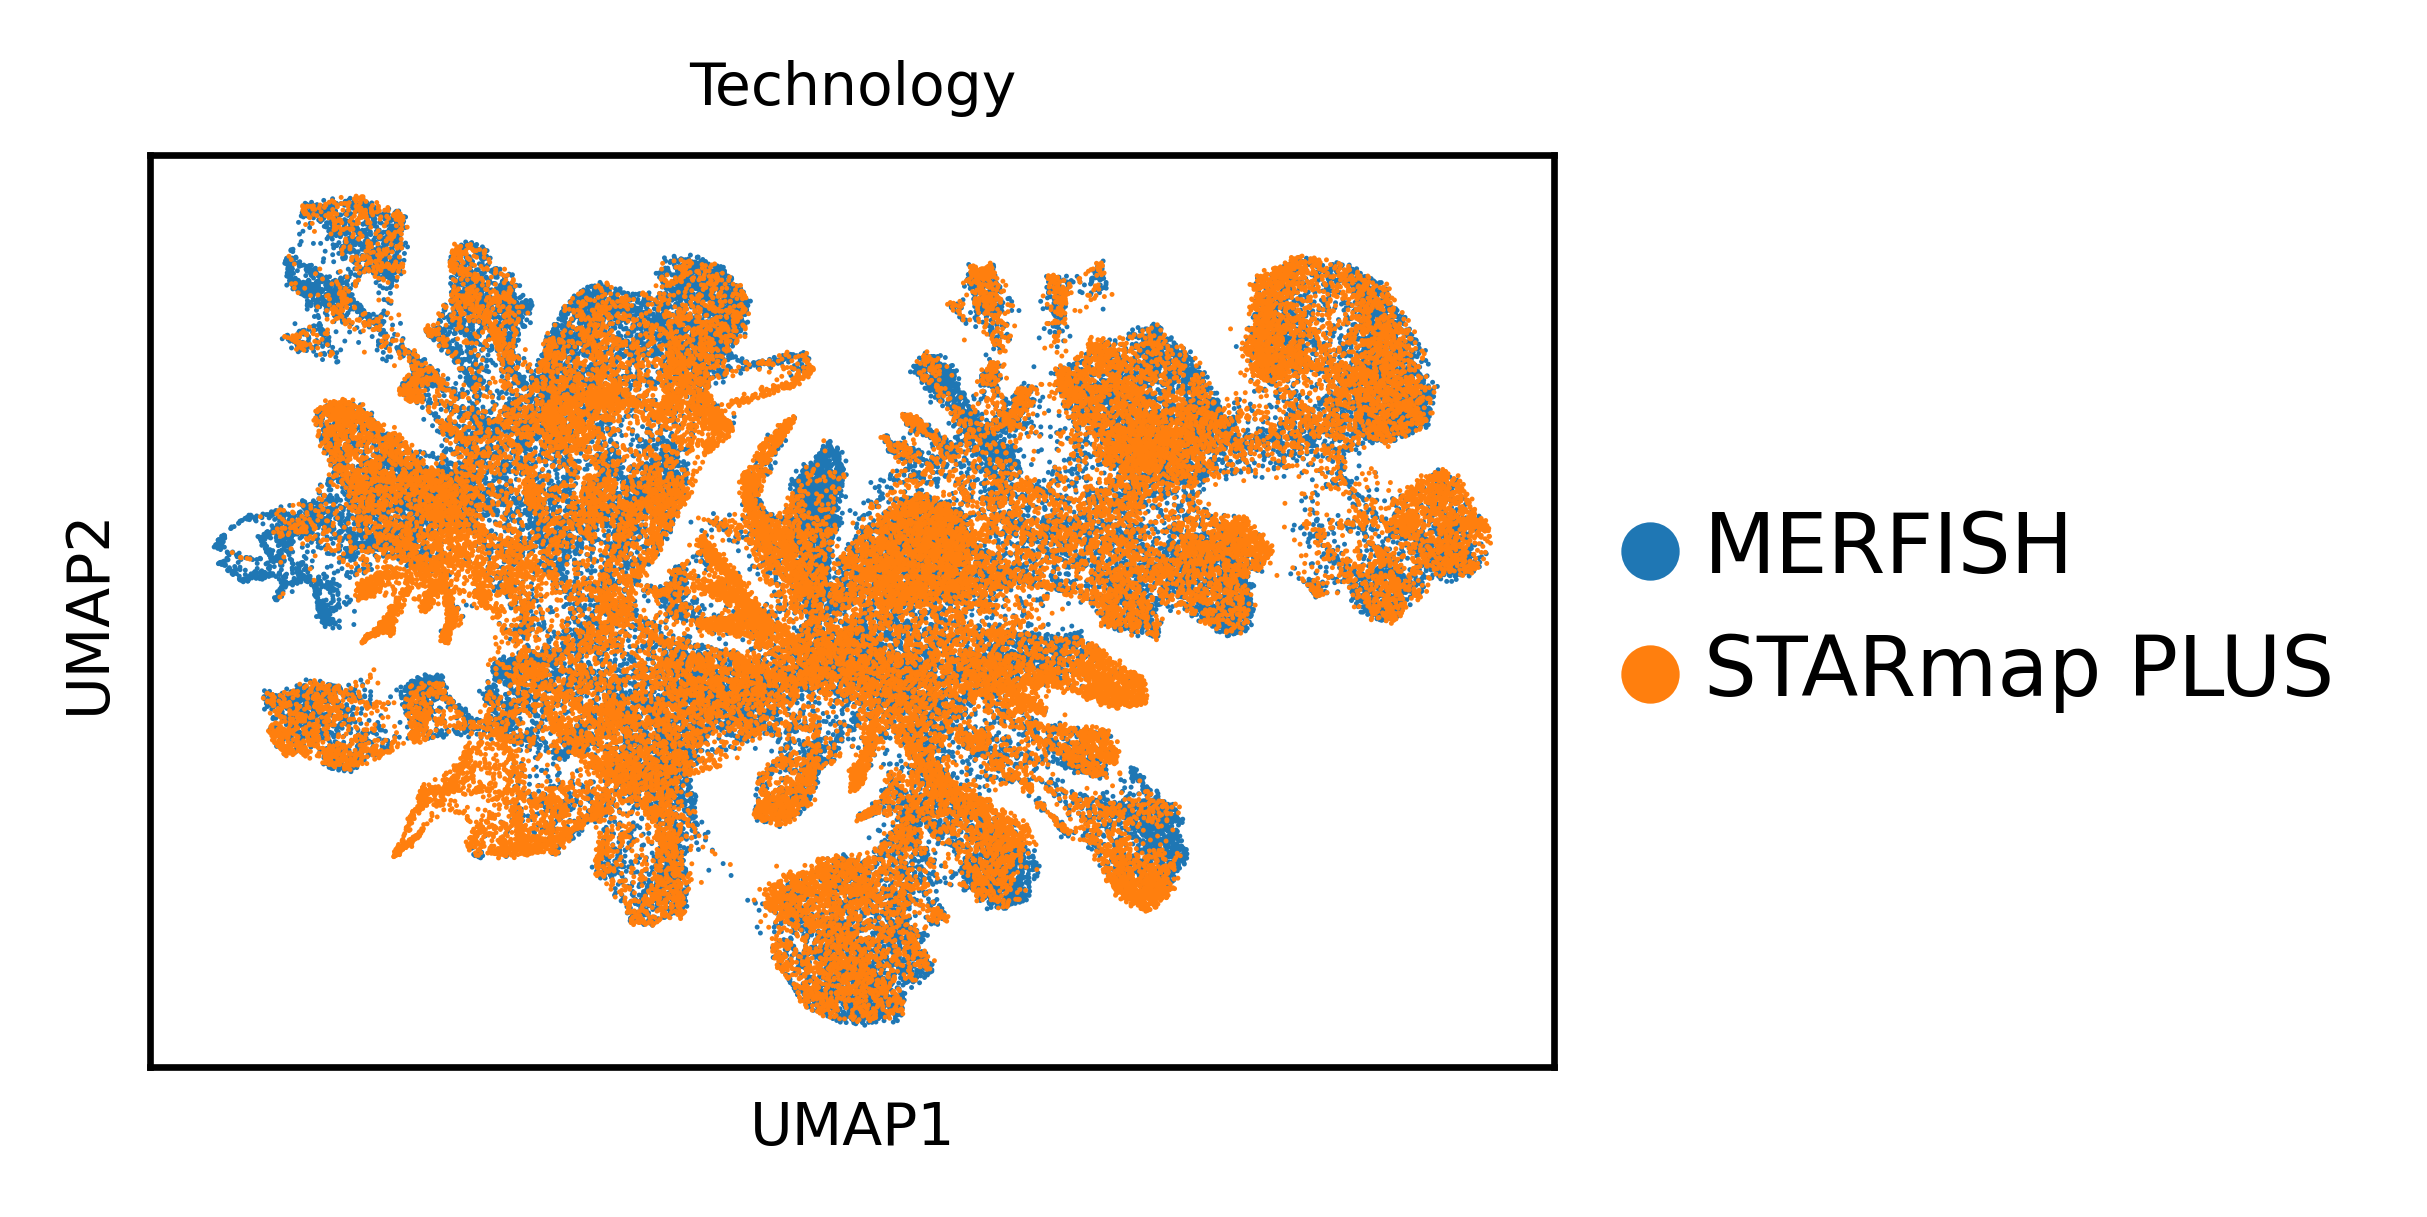

/tmp/ipykernel_4020616/3447051690.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  base = plt.cm.get_cmap("turbo", n)   # or "hsv", "nipy_spectral"


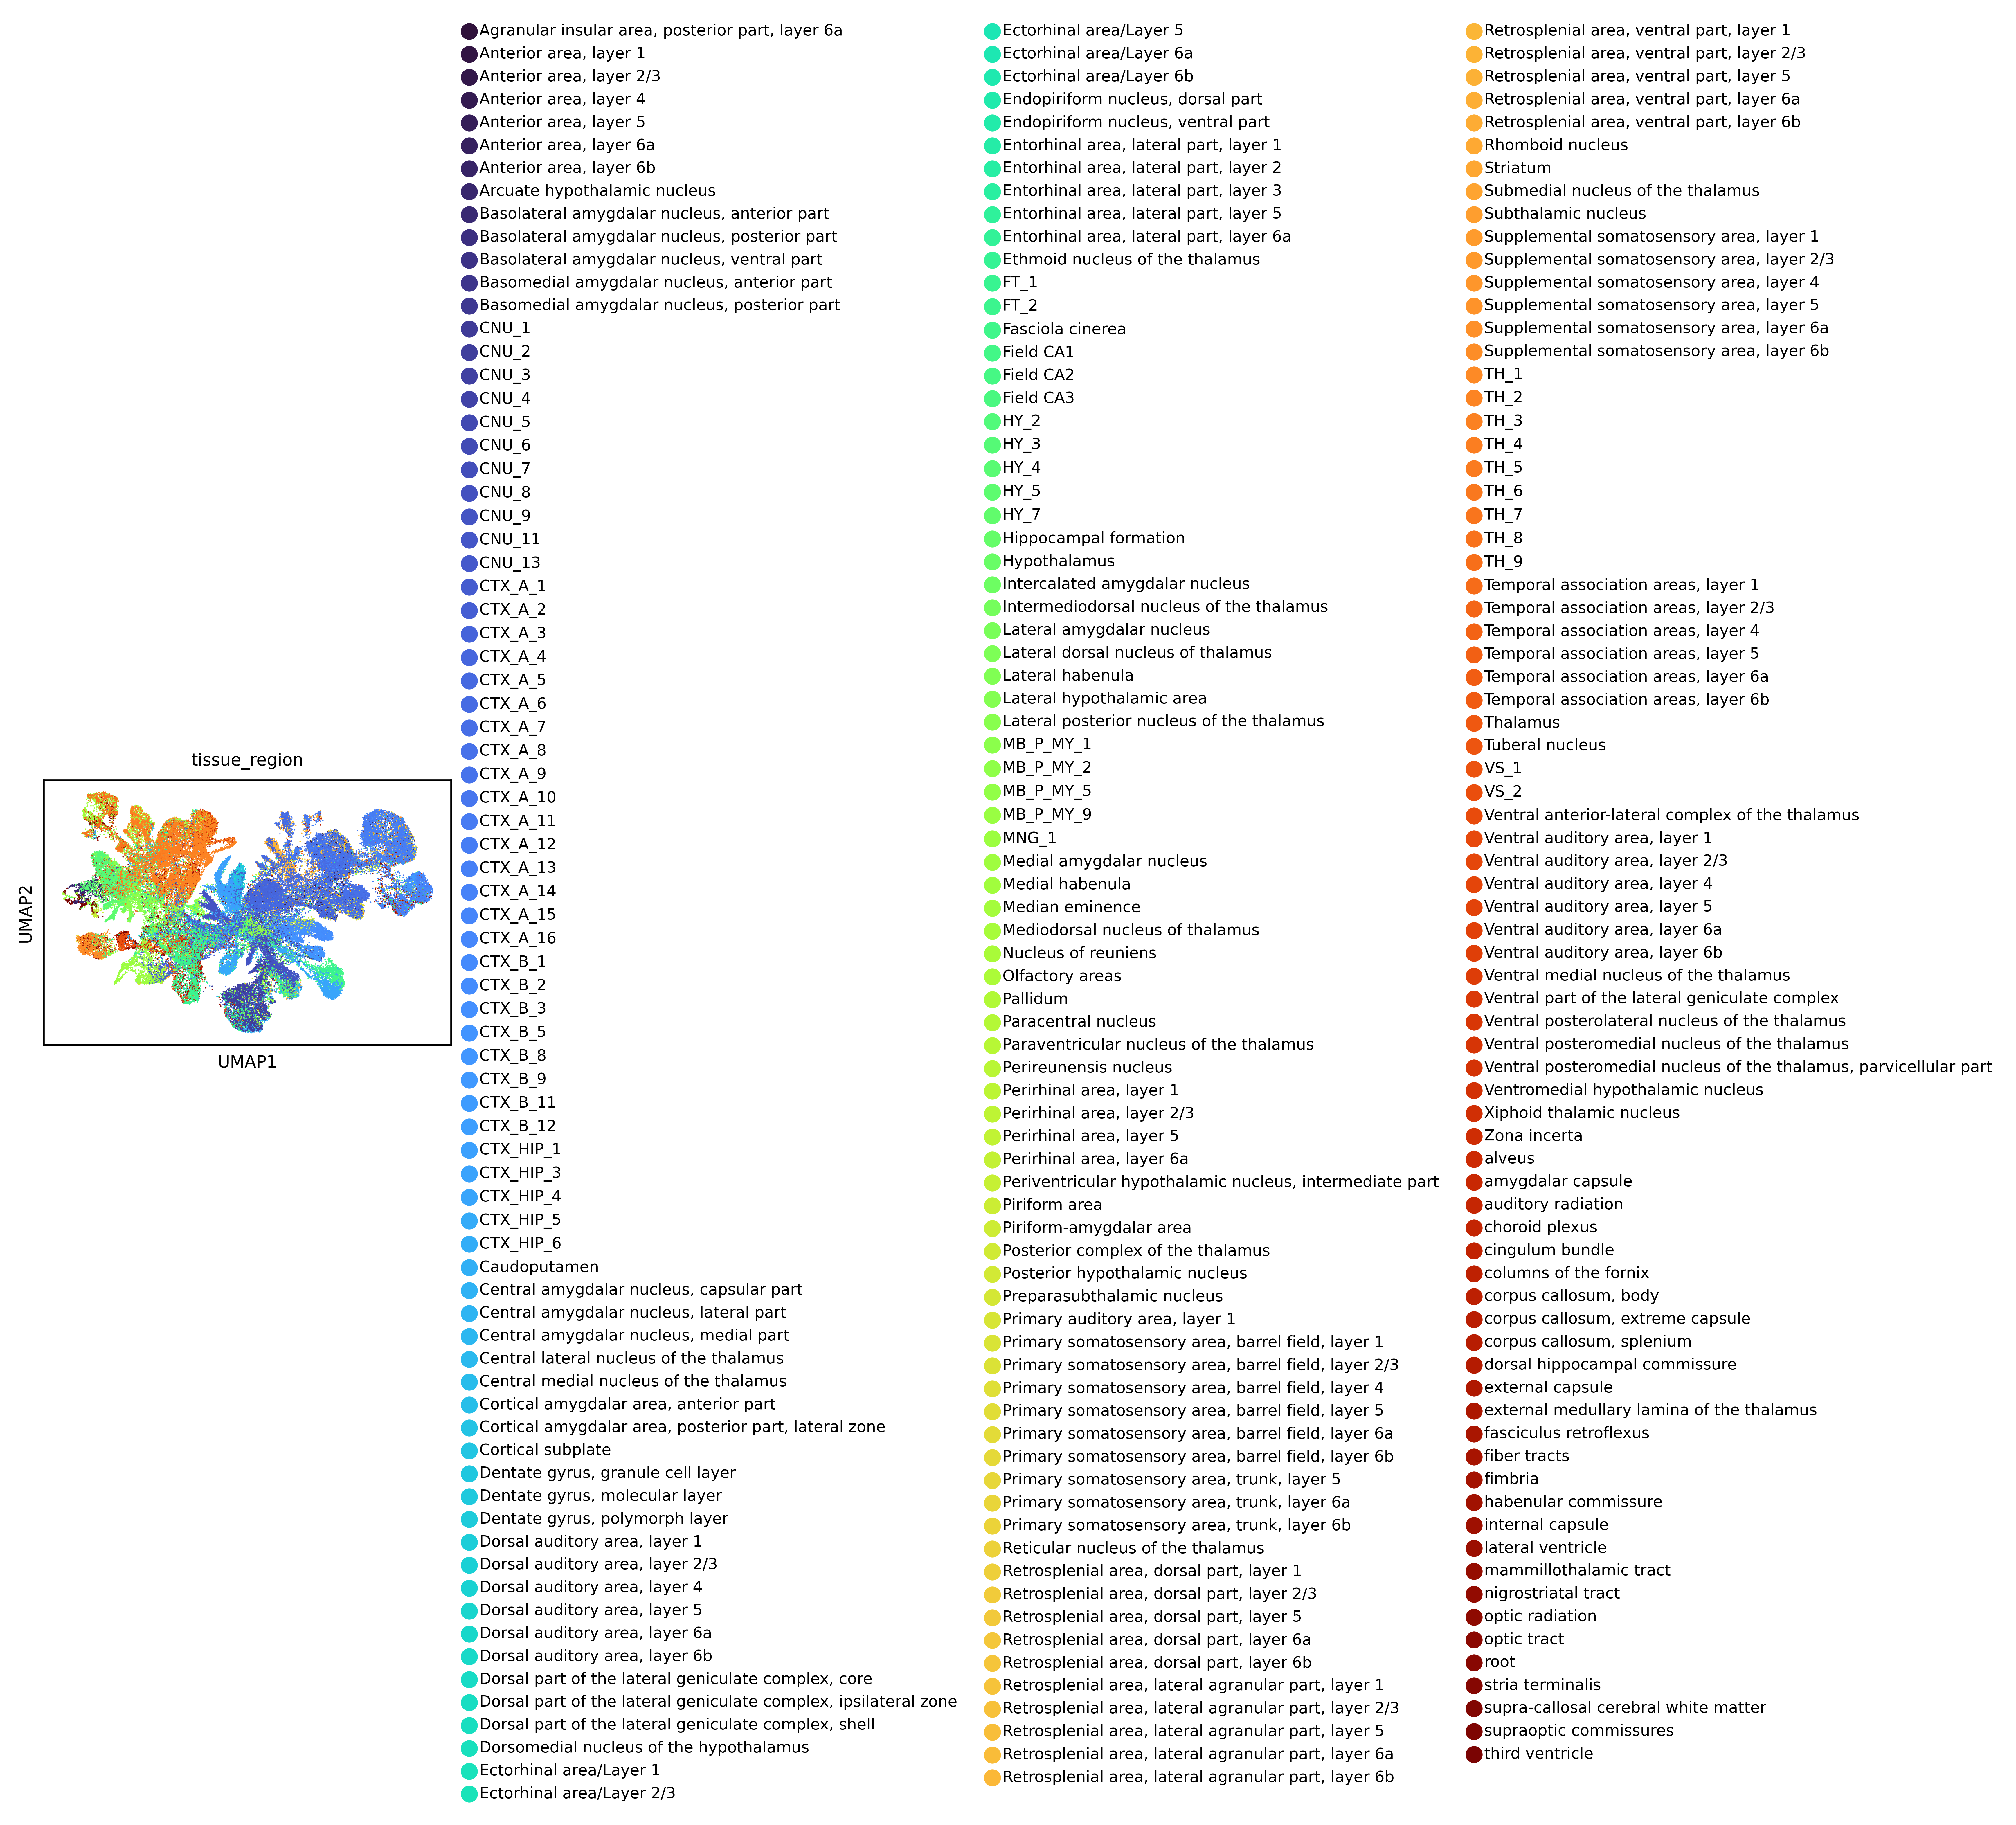

In [550]:
sc.pp.neighbors(adata, n_neighbors=15, use_rep=emb_key,
                n_pcs=n_pcs, key_added=emb_key)
sc.tl.umap(adata, neighbors_key=emb_key)

n_pcs_string = f"_{n_pcs}_pcs" if n_pcs else ""
adata.obs[batch_key] = adata.obs[batch_key].astype('category')
categories = adata.obs[batch_key].cat.categories.tolist()
assert len(categories) == 2, "Expected exactly 2 categories for batch_key"
rename = dict(zip(sorted(categories), ["MERFISH", "STARmap PLUS"]))
adata.obs[batch_key] = adata.obs[batch_key].map(rename).astype("category")

sc.pl.umap(
    adata,
    color=batch_key,
    title="Technology",
    legend_loc="right margin",
    legend_fontsize=10,
    show=False,
)
for collection in plt.gca().collections:
    collection.set_rasterized(True)
plt.savefig(
    f"{ablation_artifacts_folder_path}/{ablation_params['method']}/{ablation_params['model_timestamp']}/{dataset_name}_{emb_key}_umap_by_{batch_key}{n_pcs_string}.svg",
    format="svg", bbox_inches="tight"
)
plt.show()
plt.close()

for label_key in label_keys:
    n_cats = adata.obs[label_key].nunique()
    palette = make_large_cmap(n_cats)
    sc.pl.umap(adata, color=label_key, palette=palette, show=False)
    for collection in plt.gca().collections:
        collection.set_rasterized(True)
    plt.savefig(
        f"{ablation_artifacts_folder_path}/{ablation_params['method']}/{ablation_params['model_timestamp']}/{dataset_name}_{emb_key}_umap_by_{label_key}{n_pcs_string}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

In [551]:
# Write to disk
adata.write_h5ad(f"{ablation_artifacts_folder_path}/{ablation_params['method']}/{ablation_params['model_timestamp']}/{dataset_name}_embedded.h5ad")

### 2.3 Visualize Niches

In [552]:
adata = sc.read_h5ad(f"{ablation_artifacts_folder_path}/{ablation_params['method']}/{ablation_params['model_timestamp']}/{dataset_name}_embedded.h5ad")

In [556]:
ablation_params['latent_leiden_resolution'] = 1.0

In [557]:
# Plot embedding-based clusters
latent_cluster_key = f"{emb_key}_clusters_res_{ablation_params['latent_leiden_resolution']}"

sc.tl.leiden(adata,
             neighbors_key=emb_key,
             key_added=latent_cluster_key,
             resolution=ablation_params['latent_leiden_resolution'],
             flavor="igraph",
             n_iterations=2)

In [558]:
print(adata.obs[latent_cluster_key].nunique())
print(adata.obs[latent_cluster_key].value_counts())

41
neighborhood_emb_clusters_res_1.0
14    5646
12    5522
22    5097
28    4137
10    3935
4     3932
23    3672
17    3468
35    3253
26    3211
6     2987
18    2961
15    2940
7     2788
20    2694
19    2395
2     2228
11    2150
3     2039
39    1929
37    1740
25    1508
32    1488
34    1433
1     1414
0     1317
9     1215
16    1185
8     1166
29    1143
5      931
33     846
38     678
13     547
40     543
30     396
27     347
36     336
21     271
31     150
24      66
Name: count, dtype: int64


In [491]:
# Write to disk
adata.write_h5ad(f"{ablation_artifacts_folder_path}/{ablation_params['method']}/{ablation_params['model_timestamp']}/{dataset_name}_embedded_clustered.h5ad")

In [492]:
adata = sc.read_h5ad(f"{ablation_artifacts_folder_path}/{ablation_params['method']}/{ablation_params['model_timestamp']}/{dataset_name}_embedded_clustered.h5ad")

In [493]:
latent_cluster_key = f"{emb_key}_clusters_res_{ablation_params['latent_leiden_resolution']}"

/tmp/ipykernel_4020616/244618072.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/stjepa_v2/lib/python3.10/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


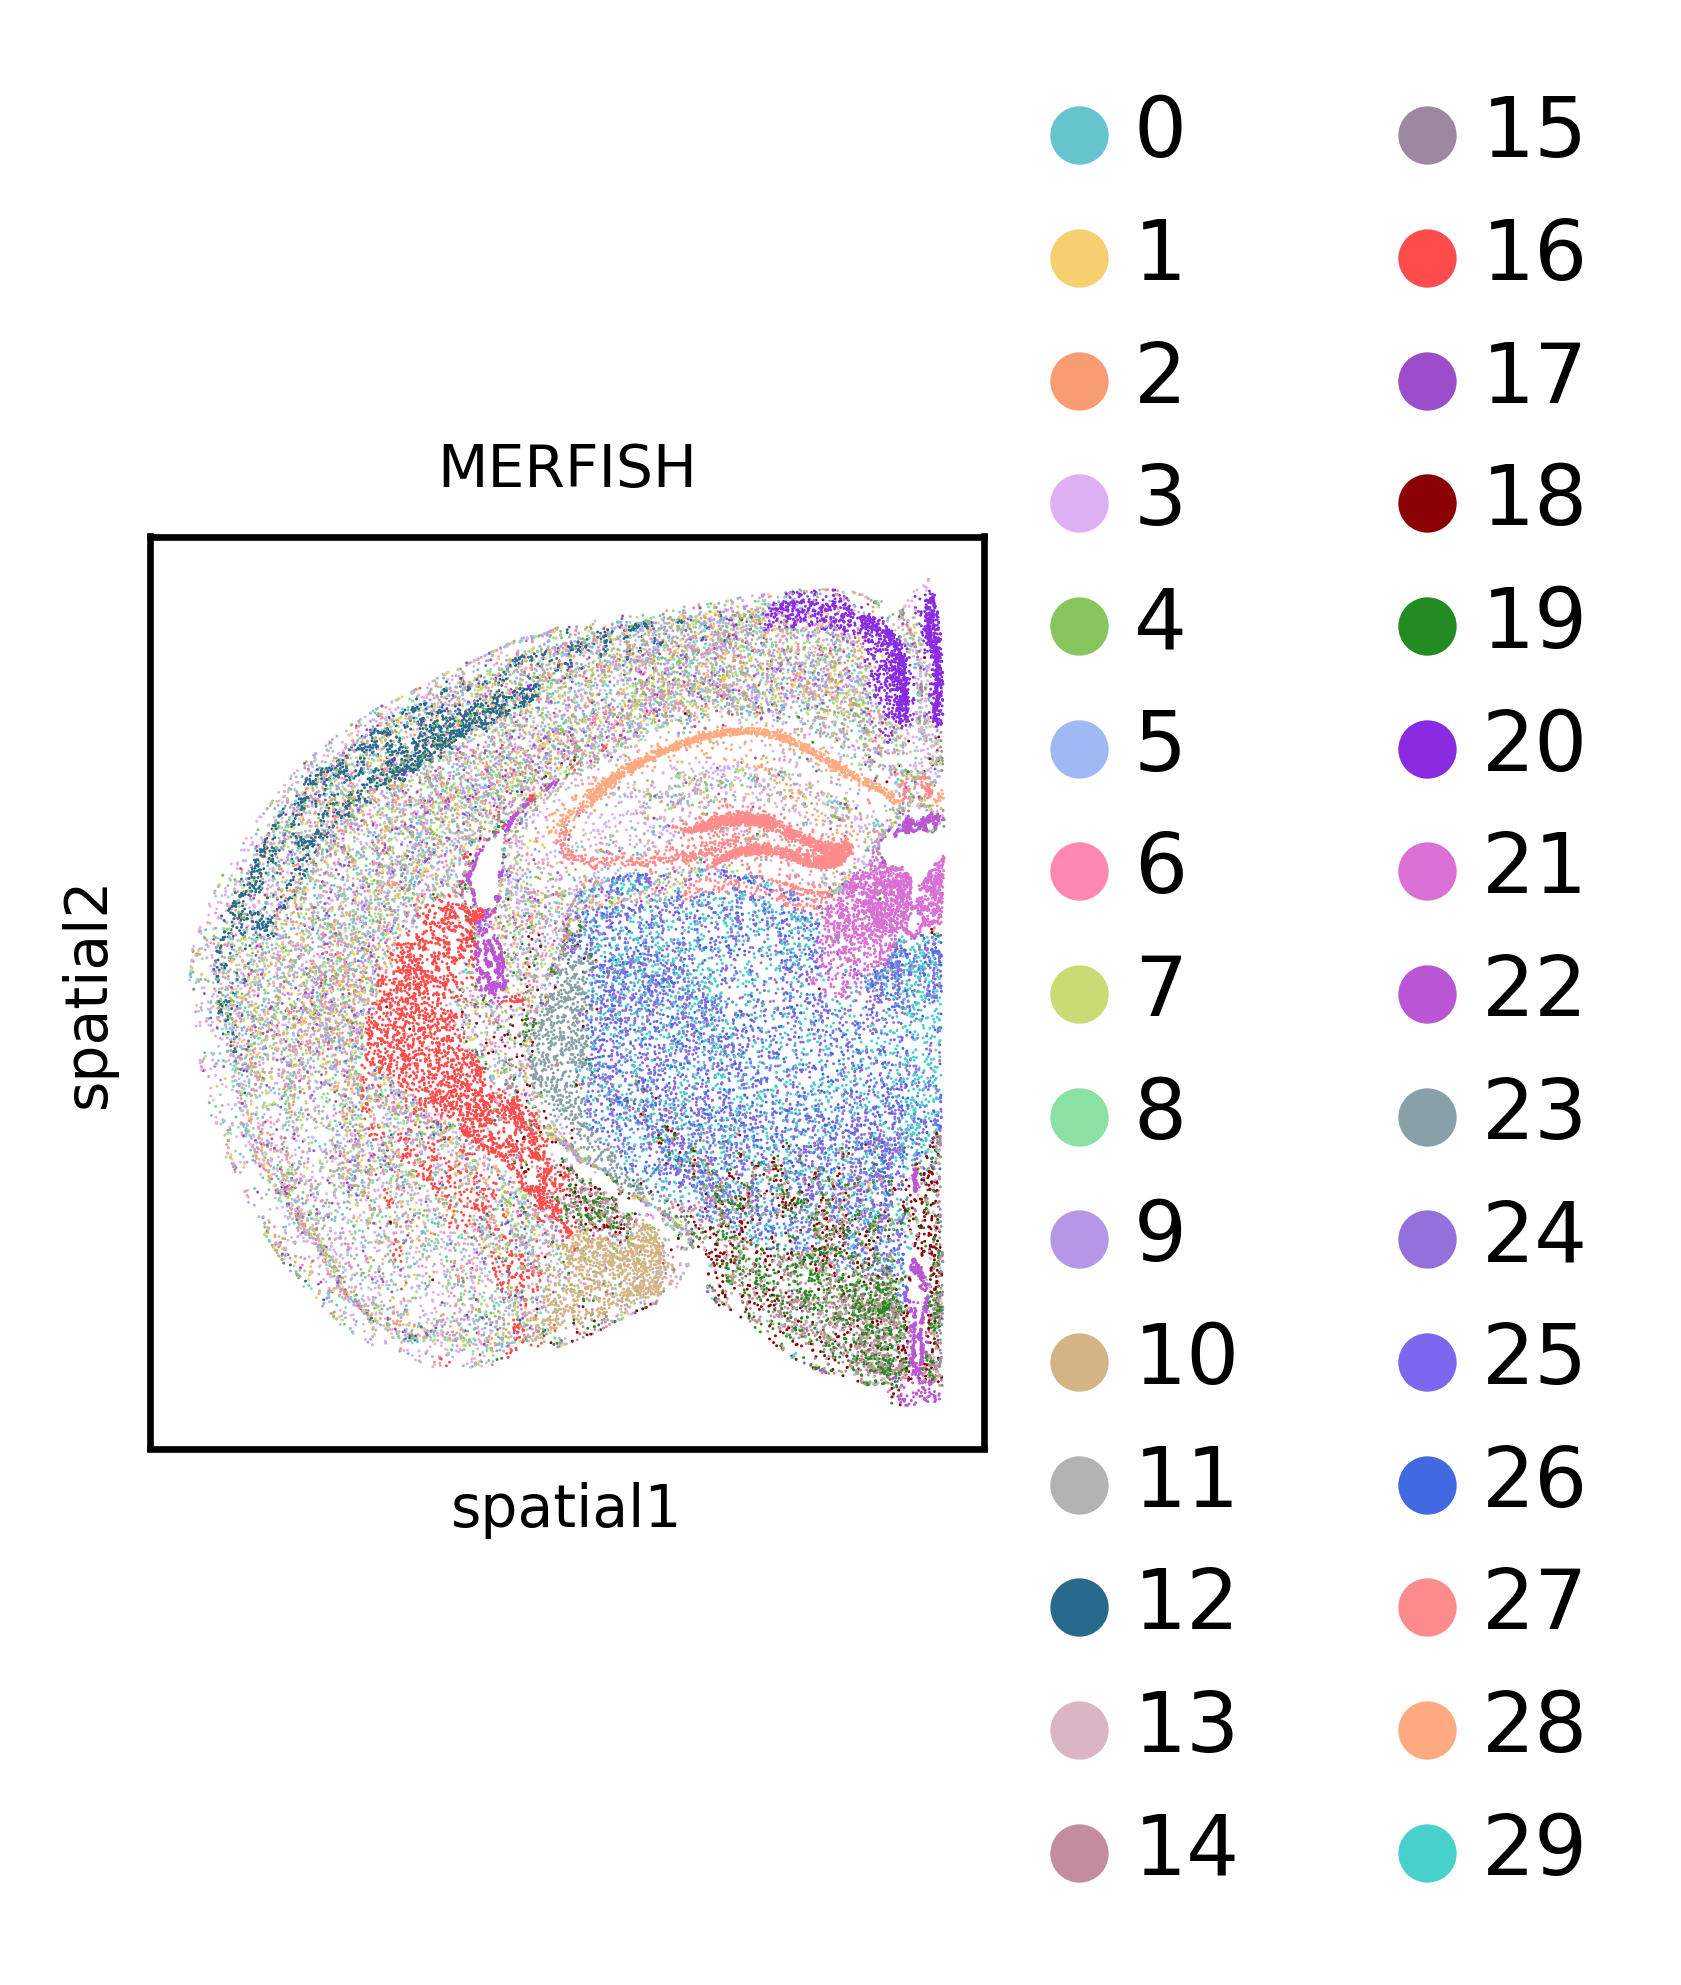

/tmp/ipykernel_4020616/244618072.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/stjepa_v2/lib/python3.10/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


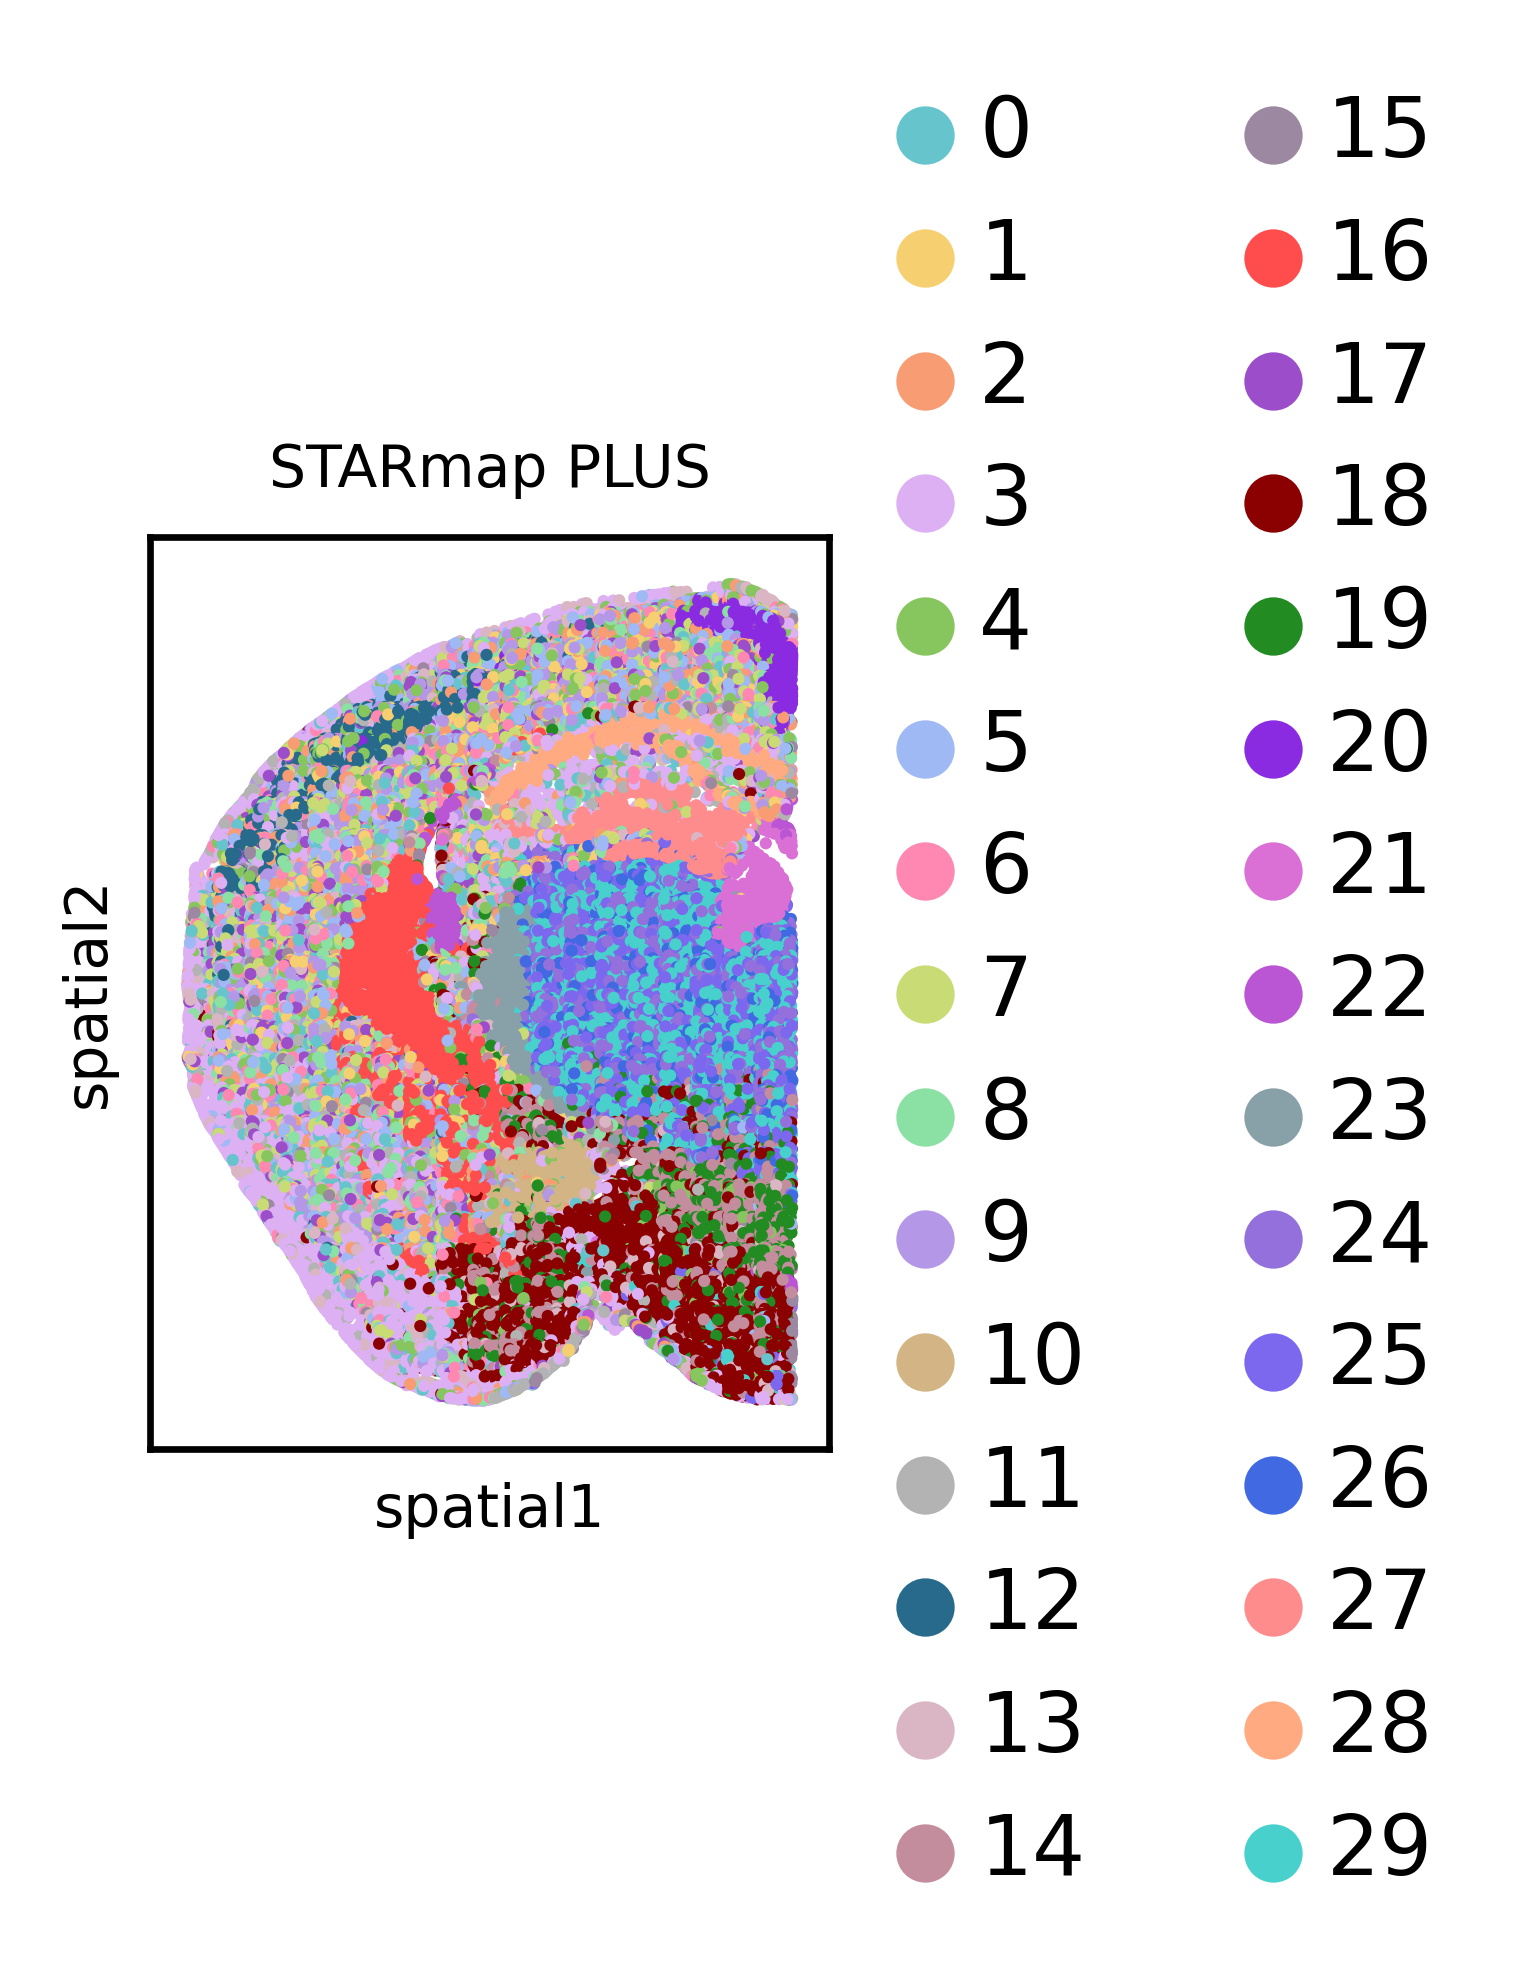

In [494]:
samples = adata.obs[batch_key].unique().tolist()
for sample in samples:
    adata_sample = adata[adata.obs[batch_key] == sample]
    sc.pl.spatial(
        adata_sample,
        color=latent_cluster_key,
        palette=custom_palette,
        spot_size=spot_sizes[sample],
        title=sample,
        legend_loc="right margin",
        legend_fontsize=10,
        show=False,
    )

    fig = plt.gcf()
    for ax in fig.axes:
        for child in ax.get_children():
            if isinstance(child, mpl.image.AxesImage):
                child.set_rasterized(True)
        for collection in ax.collections:
            collection.set_rasterized(True)

    plt.savefig(
        f"{ablation_artifacts_folder_path}/{ablation_params['method']}/{ablation_params['model_timestamp']}/tissue_{sample}_by_{latent_cluster_key}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

### 2.4 Compute Metrics

In [495]:
# Compute average cosine similarity of embeddings
X = adata.obsm[emb_key]
X = X / np.linalg.norm(X, axis=1, keepdims=True)
n = X.shape[0]
S = X.sum(axis=0)
avg_cos_sim = (S @ S - n) / (n * (n - 1))
print(f'{emb_key} average cosine similarity: {avg_cos_sim}')

cos_sim_result = pd.DataFrame([{
    "emb_key": emb_key,
    "avg_cosine_similarity": avg_cos_sim,
}])

out_path = (
    f"{ablation_artifacts_folder_path}/{ablation_params['method']}/{ablation_params['model_timestamp']}/"
    f"{dataset_name}_{emb_key}_avg_cosine_similarity.csv"
)
cos_sim_result.to_csv(out_path, index=False)
print(f"Saved → {out_path}")

neighborhood_emb average cosine similarity: 0.16028201580047607
Saved → /nfs/team361/sb75/stjepa-reproducibility/artifacts/ablation/stjepa_v2_coord_aligned/14042026_003429_740/mmb0-1b_smb1-1b_1p_coord_aligned_neighborhood_emb_avg_cosine_similarity.csv


In [496]:
# Compute NMI and ARI with region annotations
results = []
for region_key in ["Sub_molecular_tissue_region", "ccf_region_name"]:
    mask = adata.obs[region_key].notna()
    labels_true = adata.obs.loc[mask, region_key]
    labels_pred = adata.obs.loc[mask, latent_cluster_key]
    nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
    ari = skm.adjusted_rand_score(labels_true, labels_pred)
    print(f"NMI ({region_key}): {nmi:.4f}")
    print(f"ARI ({region_key}): {ari:.4f}")
    results.append({"region_key": region_key, "NMI": nmi, "ARI": ari})

df = pd.DataFrame(results)
df.to_csv(
    f"{ablation_artifacts_folder_path}/{ablation_params['method']}/{ablation_params['model_timestamp']}/{dataset_name}_{latent_cluster_key}_niche_identification_metrics.csv",
    index=False
)

NMI (Sub_molecular_tissue_region): 0.3636
ARI (Sub_molecular_tissue_region): 0.1633
NMI (ccf_region_name): 0.3648
ARI (ccf_region_name): 0.1706


In [497]:
# Compute batch integration metrics
results = []

# iLISI
batch = adata.obs[batch_key].values
knn = pynndescent(adata.obsm[emb_key], n_neighbors=90)
ilisi = float(np.mean(ilisi_knn(knn, batch)))
print(f"iLISI: {ilisi:.4f}")
results.append({"metric": "iLISI", "score": ilisi})

# ASW
asw = silhouette_score(
    adata.obsm[emb_key],
    adata.obs["batch"],
    metric="euclidean",
    sample_size=10000
)
print(f"ASW batch: {asw:.4f}")
results.append({"metric": "ASW", "score": asw})

# MMD
mmd_score = mmd_comparable(adata, emb_key, batch_key)
print(f"MMD: {mmd_score:.4f}")
results.append({"metric": "MMD", "score": mmd_score})

# Save
df = pd.DataFrame(results)
df.to_csv(
    f"{ablation_artifacts_folder_path}/{ablation_params['method']}/{ablation_params['model_timestamp']}/{dataset_name}_{emb_key}_batch_integration_metrics.csv",
    index=False
)

iLISI: 0.8503
ASW batch: 0.0008
MMD: 0.0012


In [498]:
# --- Config -----------------------------------------------------------
latent_leiden_resolution = 1.0
N_STEPS   = 4      # points above and below base resolution
STEP_SIZE = 0.1
MIN_RES   = 0.1    # Leiden resolution must be > 0

region_keys = ["Sub_molecular_tissue_region", "ccf_region_name"]

# Build resolution grid: N_STEPS below and above base, clamped to MIN_RES
# Use integer steps to avoid float accumulation errors in np.arange
base_int = round(latent_leiden_resolution / STEP_SIZE)  # e.g. 1.0/0.1 -> 10
resolutions = [
    round(step * STEP_SIZE, 1)
    for step in range(base_int - N_STEPS, base_int + N_STEPS + 1)
    if step * STEP_SIZE >= MIN_RES
]

# --- Sweep ------------------------------------------------------------
all_results = []

for res in resolutions:
    cluster_key = f"{emb_key}_clusters_res_{res}"

    # Leiden clustering
    try:
        rsc.tl.leiden(adata,
                      neighbors_key=emb_key,
                      key_added=cluster_key,
                      resolution=res,
                      flavor="igraph",
                      n_iterations=2)
    except NameError:
        sc.tl.leiden(adata,
                     neighbors_key=emb_key,
                     key_added=cluster_key,
                     resolution=res,
                     flavor="igraph",
                     n_iterations=2)

    n_clusters = adata.obs[cluster_key].nunique()
    print(f"\n── Resolution {res:.1f}  ({n_clusters} clusters) ──")

    for region_key in region_keys:
        mask        = adata.obs[region_key].notna()
        labels_true = adata.obs.loc[mask, region_key]
        labels_pred = adata.obs.loc[mask, cluster_key]

        nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
        ari = skm.adjusted_rand_score(labels_true, labels_pred)
        print(f"  {region_key:40s}  NMI={nmi:.4f}  ARI={ari:.4f}")

        all_results.append({
            "resolution": res,
            "n_clusters": n_clusters,
            "region_key": region_key,
            "NMI":        nmi,
            "ARI":        ari,
        })

# --- Save -------------------------------------------------------------
df = pd.DataFrame(all_results)

# Canonical column order
df = df[["resolution", "n_clusters", "region_key", "NMI", "ARI"]]

out_path = (
    f"{ablation_artifacts_folder_path}/{ablation_params['method']}/{ablation_params['model_timestamp']}/"
    f"{dataset_name}_{emb_key}_niche_identification_metrics_res_sweep.csv"
)
df.to_csv(out_path, index=False)
print(f"\nSaved {len(df)} rows → {out_path}")


── Resolution 0.6  (14 clusters) ──
  Sub_molecular_tissue_region               NMI=0.3782  ARI=0.1425
  ccf_region_name                           NMI=0.3738  ARI=0.0883

── Resolution 0.7  (15 clusters) ──
  Sub_molecular_tissue_region               NMI=0.3833  ARI=0.1517
  ccf_region_name                           NMI=0.3796  ARI=0.0932

── Resolution 0.8  (16 clusters) ──
  Sub_molecular_tissue_region               NMI=0.3905  ARI=0.1567
  ccf_region_name                           NMI=0.3918  ARI=0.0998

── Resolution 0.9  (15 clusters) ──
  Sub_molecular_tissue_region               NMI=0.3847  ARI=0.1528
  ccf_region_name                           NMI=0.3797  ARI=0.0936

── Resolution 1.0  (18 clusters) ──
  Sub_molecular_tissue_region               NMI=0.3798  ARI=0.1811
  ccf_region_name                           NMI=0.3837  ARI=0.1178

── Resolution 1.1  (18 clusters) ──
  Sub_molecular_tissue_region               NMI=0.3785  ARI=0.1812
  ccf_region_name                        